In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("/raid/scratch/mdhossa2025/mdhossa/VWA-Training/LLaMA-Factory")

plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Nimbus Roman", "DejaVu Serif"],
        "mathtext.fontset": "dejavuserif",
        "font.size": 11,
        "axes.labelsize": 11.5,
        "axes.titlesize": 12,
        "xtick.labelsize": 10.5,
        "ytick.labelsize": 10.5,
        "legend.fontsize": 10,
        "axes.linewidth": 0.6,
        "xtick.major.width": 0.6,
        "ytick.major.width": 0.6,
        "xtick.major.size": 2.5,
        "ytick.major.size": 2.5,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "legend.frameon": False,
        "figure.dpi": 120,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.02,
    }
)

COL_3B = "#8FC3B8"
COL_7B = "#2E6E62"
COL_3B_ED = "#6FA298"
COL_7B_ED = "#24574E"
GRID_KW = dict(axis="y", color="0.88", lw=0.5, zorder=0)
W2 = 6.30

TEACHERS = {
    "7b": {
        "label": "7B teacher",
        "cache": ROOT / "cache/rlhf_v_mwspo_weak_lp.parquet",
        "color": COL_7B,
        "edge": COL_7B_ED,
        "output": ROOT / "results/figures/weak_grounding_hist_7b",
    },
    "3b": {
        "label": "3B teacher",
        "cache": ROOT / "cache/rlhf_v_mwspo_weak_lp_qwen3b.parquet",
        "color": COL_3B,
        "edge": COL_3B_ED,
        "output": ROOT / "results/figures/weak_grounding_hist_3b",
    },
}


def load_margins(path: Path) -> pd.DataFrame:
    df = pd.read_parquet(path)
    out = pd.DataFrame(index=df.index)
    out["delta_img"] = df["weak_aligned_lp_yw_mw"] - df["weak_ref_lp_yw_mw"] - (
        df["weak_aligned_lp_yw_ml"] - df["weak_ref_lp_yw_ml"]
    )
    out["delta_resp"] = df["weak_aligned_lp_yw_mw"] - df["weak_ref_lp_yw_mw"] - (
        df["weak_aligned_lp_yl_mw"] - df["weak_ref_lp_yl_mw"]
    )
    return out


def style_axis(ax: plt.Axes) -> None:
    ax.spines["bottom"].set_color("black")
    ax.spines["bottom"].set_linewidth(0.9)
    ax.spines["bottom"].set_zorder(6)
    ax.spines["left"].set_color("0.25")
    ax.grid(**GRID_KW)
    ax.set_axisbelow(True)


def plot_histograms(margins: pd.DataFrame, color: str, edge: str, bins: int = 22, save_prefix=None):
    panels = (
        (margins["delta_img"], r"$\Delta_{\mathrm{img}}^w=\hat{s}_M-\hat{s}_I$"),
        (margins["delta_resp"], r"$\Delta_{\mathrm{resp}}^w=\hat{s}_M-\hat{s}_R$"),
    )
    fig, axes = plt.subplots(1, 2, figsize=(W2, 2.4))
    for ax, (values, xlabel) in zip(axes, panels):
        values = values.replace([np.inf, -np.inf], np.nan).dropna()
        lo, hi = values.quantile([0.01, 0.99])
        shown = values[values.between(lo, hi)]
        weights = np.full(len(shown), 1.0 / len(values))
        ax.hist(
            shown,
            bins=bins,
            range=(float(lo), float(hi)),
            weights=weights,
            color=color,
            edgecolor=edge,
            linewidth=0.35,
            rwidth=1.0,
            zorder=3,
        )
        ax.set_xlim(float(lo), float(hi))
        ax.axvline(0.0, color="0.25", linestyle="--", linewidth=0.8, zorder=4)
        pct = float((values > 0).mean() * 100.0)
        ax.text(0.97, 0.92, f"{pct:.1f}% $>0$", transform=ax.transAxes, ha="right", va="top", fontsize=11.5)
        ax.set_xlabel(xlabel)
        style_axis(ax)
    axes[0].set_ylabel("Fraction of examples")
    # Increased gap between the two subplots:
    fig.subplots_adjust(wspace=0.20, left=0.09, right=0.99, top=0.96, bottom=0.26)
    if save_prefix is not None:
        save_prefix = Path(save_prefix)
        save_prefix.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_prefix.with_suffix(".pdf"), dpi=1500)
        fig.savefig(save_prefix.with_suffix(".png"), dpi=1500)
        print(f"Saved {save_prefix.with_suffix('.pdf')}")
        print(f"Saved {save_prefix.with_suffix('.png')}")
    plt.show()
    return fig


def run_teacher(key: str, bins: int = 22):
    spec = TEACHERS[key]
    margins = load_margins(spec["cache"])
    print(
        f"{spec['label']}: n={len(margins)}  "
        f"%Δ_img>0={(margins['delta_img'] > 0).mean() * 100:.1f}  "
        f"%Δ_resp>0={(margins['delta_resp'] > 0).mean() * 100:.1f}"
    )
    return plot_histograms(margins, spec["color"], spec["edge"], bins=bins, save_prefix=spec["output"])

7B teacher: n=5733  %Δ_img>0=96.2  %Δ_resp>0=93.0
Saved /raid/scratch/mdhossa2025/mdhossa/VWA-Training/LLaMA-Factory/results/figures/weak_grounding_hist_7b.pdf
Saved /raid/scratch/mdhossa2025/mdhossa/VWA-Training/LLaMA-Factory/results/figures/weak_grounding_hist_7b.png


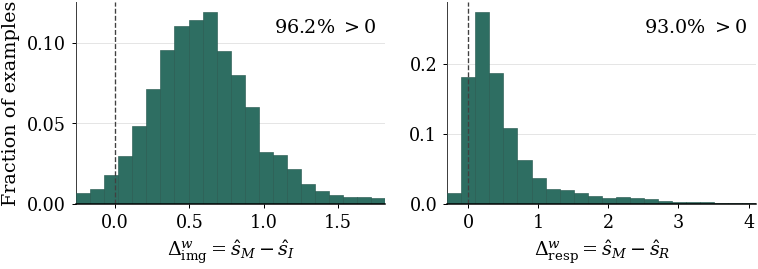

3B teacher: n=5733  %Δ_img>0=73.6  %Δ_resp>0=77.7
Saved /raid/scratch/mdhossa2025/mdhossa/VWA-Training/LLaMA-Factory/results/figures/weak_grounding_hist_3b.pdf
Saved /raid/scratch/mdhossa2025/mdhossa/VWA-Training/LLaMA-Factory/results/figures/weak_grounding_hist_3b.png


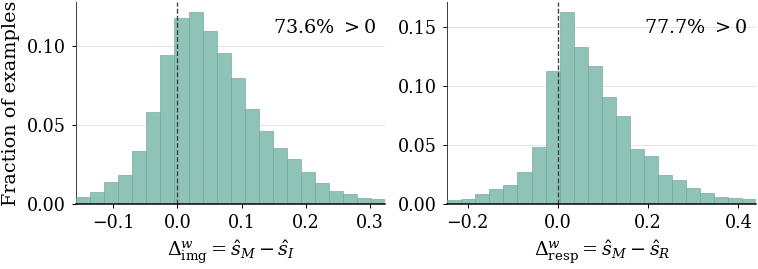

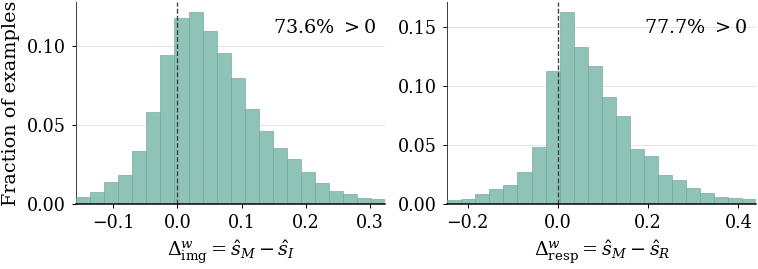

In [8]:
run_teacher("7b")
run_teacher("3b")

In [ ]:
"""
Data-efficiency figures for m-WSPO.

The claim: m-WSPO reaches its performance with ~5.7k preference pairs, and
the 21.4k-pair baselines do not get there with ~4x the data.

Encoding: preference-data size is a CONTINUOUS log axis, and every method is
drawn only at the budget it was actually trained on. m-WSPO's line simply
ends at 5.7k, so nothing implies a missing m-WSPO run at 21.4k. Up-and-left
is better; the frontier reads directly off the plot.

  fig_efficiency   m-WSPO vs mDPO / SymMPO, 2x2 panels
  fig_frontier     every method in the main table, same panels

SOURCES
    Main results table: all methods at their own data size, one protocol.
    Ablation table: supplies m-WSPO's 3k point.
    The two tables agree on m-WSPO at 5.73k for POPE Acc (85.53 vs 85.6) and
    POPE F1 (84.14 vs 84.1), so mixing them is safe for those metrics. They
    disagree on MMStar (36.7 vs 33.7), so MMStar's 3k point is left out
    until that is resolved -- set it in OURS below once it is.

Outputs .pdf (for LaTeX) and .png (for eyeballing).
"""

import matplotlib
if __name__ == "__main__":
    # In a notebook, run `%matplotlib inline` in a cell above instead --
    # matplotlib.use() sticks for the whole kernel session.
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

# --------------------------------------------------------------------------
# STYLE
# --------------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Nimbus Roman", "DejaVu Serif"],
    "mathtext.fontset": "dejavuserif",
    "font.size": 8,
    "axes.labelsize": 8.5,
    "axes.titlesize": 9.5,
    "xtick.labelsize": 8.0,
    "ytick.labelsize": 8.2,
    "legend.fontsize": 7.6,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "figure.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
})

C_OURS = "#2E6E62"
C_MDPO = "#B5763A"
C_SYMM = "#7A7FB0"
C_BASE = "0.45"
C_OTHER = "#9AA5B1"

# --------------------------------------------------------------------------
# DATA
# --------------------------------------------------------------------------
PANELS = [  # (title, key, MIN_SPAN, higher_is_better)
    ("POPE Acc",                       "pope_acc",    2.0,  True),
    (r"MMHal-Bench Hall $\downarrow$", "mmhal_hall",  0.12, False),
    ("MMStar",                         "mmstar",      2.0,  True),
    ("HallusionBench aAcc",            "aacc",        2.0,  True),
]

# swap the second entry for this to show the GPT-4-judged Score column
# instead, where m-WSPO ranks 10th of 12 rather than 4th of 12:
#     (r"MMHal-Bench Score $\uparrow$", "mmhal_score", 0.60, True),

# base LLaVA-1.5-7B, no preference data -- drawn as a dashed rule
BASE = {"pope_acc": 71.8, "pope_f1": 74.5, "mmstar": 33.3, "aacc": 41.71,
        "mmhal_score": 2.26, "mmhal_hall": 0.562}

# m-WSPO at its own budgets. None = not available / unresolved.
#   3k   -> ablation table
#   5.73k-> main results table
OURS = {
    "pope_acc": [(3.0, 85.6), (5.73, 85.53)],
    "pope_f1":  [(3.0, 84.2), (5.73, 84.14)],
    "mmstar":   [(5.73, 36.7)],          # 3k pending: 33.6 (abl) vs 36.7 (main)
    "aacc":     [(5.73, 44.56)],         # HallusionBench absent from ablation
    "mmhal_score": [(5.73, 2.10)],       # MMHal absent from ablation
    "mmhal_hall":  [(5.73, 0.446)],
}

# the two named baselines, main results table
MDPO = {"size": 21.4, "pope_acc": 80.6, "pope_f1": 83.3, "mmstar": 34.2,
        "aacc": 42.78, "mmhal_score": 2.71, "mmhal_hall": 0.500}
SYMM = {"size": 21.4, "pope_acc": 82.6, "pope_f1": 83.7, "mmstar": 34.8,
        "aacc": 44.28, "mmhal_score": 2.89, "mmhal_hall": 0.427}

# every other method, for the frontier figure
# TRANSCRIBED FROM THE SCREENSHOT -- verify before publishing.
OTHERS = [
    ("LLaVA-RLHF", 122.0, {"pope_acc": 68.7, "pope_f1": 74.7, "mmstar": 31.4,
                           "aacc": 38.26, "mmhal_score": 2.00, "mmhal_hall": 0.667}),
    ("POVID",       17.0, {"pope_acc": 78.6, "pope_f1": 81.9, "mmstar": 34.4,
                           "aacc": 43.31, "mmhal_score": 2.28, "mmhal_hall": 0.562}),
    ("HALVA",       21.5, {"pope_acc": 78.0, "pope_f1": 83.5, "mmstar": 32.3,
                           "aacc": 42.42, "mmhal_score": 2.14, "mmhal_hall": 0.604}),
    ("HA-DPO",       6.0, {"pope_acc": 74.2, "pope_f1": 78.0, "mmstar": 32.6,
                           "aacc": 42.16, "mmhal_score": 1.97, "mmhal_hall": 0.615}),
    ("RLAIF-V",     74.8, {"pope_acc": 72.7, "pope_f1": 84.4, "mmstar": 34.6,
                           "aacc": 36.75, "mmhal_score": 3.04, "mmhal_hall": 0.396}),
    ("TPO",         21.4, {"pope_acc": 82.2, "pope_f1": 86.1, "mmstar": 34.2,
                           "aacc": 41.62, "mmhal_score": 2.76, "mmhal_hall": 0.427}),
    ("OPA-DPO",      4.8, {"pope_acc": 81.3, "pope_f1": 85.6, "mmstar": 33.1,
                           "aacc": 42.69, "mmhal_score": 2.83, "mmhal_hall": 0.469}),
    ("DPO",         21.4, {"pope_acc": 71.3, "pope_f1": 82.6, "mmstar": 33.4,
                           "aacc": 40.21, "mmhal_score": 2.44, "mmhal_hall": 0.490}),
]

SHOW_BASE = True        # dashed rule at base LLaVA-1.5-7B
GAP_NOTE = True         # "3.7x less data" marker in the first panel
NCOLS = 2

PANEL_W, PANEL_H = 1.75, 1.20
WSPACE, HSPACE = 0.42, 0.62

XTICKS = [3, 5.73, 21.4]
XTICK_LABELS = ["3k", "5.7k", "21.4k"]


def _fmt(v):
    if abs(v) >= 200:
        return f"{v:.0f}"
    if abs(v) < 1:
        return f"{v:.3f}"
    if abs(v) < 10:
        return f"{v:.2f}"
    return f"{v:.1f}"


def _frame(ax, name, vals, min_span, xlo, xhi):
    lo, hi = min(vals), max(vals)
    mid, span = (lo + hi) / 2, max(hi - lo, min_span)
    ax.set_ylim(mid - span / 2 - 0.22 * span, mid + span / 2 + 0.26 * span)
    ax.set_xscale("log")
    ax.set_xlim(xlo, xhi)
    ax.set_xticks(XTICKS)
    ax.set_xticklabels(XTICK_LABELS)
    ax.minorticks_off()
    ax.set_title(name, pad=4)
    ax.set_xlabel("preference pairs", fontsize=7.8, labelpad=2)
    ax.grid(axis="y", color="0.90", lw=0.5, zorder=0)
    ax.set_axisbelow(True)


def _grid(n, ncols):
    nrows = int(np.ceil(n / ncols))
    fig_w = PANEL_W * (ncols + (ncols - 1) * WSPACE) + 0.55
    fig_h = PANEL_H * (nrows + (nrows - 1) * HSPACE) + 0.62
    fig, axes = plt.subplots(nrows, ncols, figsize=(fig_w, fig_h),
                             gridspec_kw=dict(wspace=WSPACE, hspace=HSPACE))
    return fig, np.atleast_1d(axes).ravel()


# --------------------------------------------------------------------------
# FIG 1  --  m-WSPO vs the two named baselines
# --------------------------------------------------------------------------
def fig_efficiency(path, panels=None, ncols=NCOLS):
    panels = panels or PANELS
    fig, axes = _grid(len(panels), ncols)

    for i, (ax, (title, key, min_span, hib)) in enumerate(zip(axes, panels)):
        pts = OURS[key]
        xs = [p[0] for p in pts]
        ys = [p[1] for p in pts]
        base = BASE[key] if SHOW_BASE else None

        if base is not None:
            ax.axhline(base, color=C_BASE, lw=0.8, ls=(0, (4, 2.5)), zorder=2)

        # each method only where it was trained
        ax.plot(xs, ys, "-o", color=C_OURS, lw=1.7, ms=5.0,
                mec="white", mew=0.6, zorder=6)
        ax.plot(MDPO["size"], MDPO[key], "^", color=C_MDPO, ms=6.4,
                mec="white", mew=0.6, zorder=6)
        ax.plot(SYMM["size"], SYMM[key], "D", color=C_SYMM, ms=5.0,
                mec="white", mew=0.6, zorder=6)

        vals = ys + [MDPO[key], SYMM[key]] + ([base] if base is not None else [])
        _frame(ax, title, vals, min_span, 2.1, 34.0)

        # label ours and BOTH baselines
        ax.annotate(_fmt(ys[-1]), (xs[-1], ys[-1]), xytext=(0, 9),
                    textcoords="offset points", ha="center", va="bottom",
                    fontsize=7.2, color=C_OURS, zorder=8)

        # both baselines sit at the same x, so nudge their labels apart when
        # the two values are closer together than a line of text
        y0, y1 = ax.get_ylim()
        dpp = (y1 - y0) / (PANEL_H * 72.0)
        pair = sorted(((MDPO[key], C_MDPO), (SYMM[key], C_SYMM)))
        gap = 10.0 * dpp
        offs = [0.0, 0.0]
        if pair[1][0] - pair[0][0] < gap:
            shift = (gap - (pair[1][0] - pair[0][0])) / 2
            offs = [-shift, shift]
        for (val, col), off in zip(pair, offs):
            ax.annotate(_fmt(val), (21.4, val + off), xytext=(9, 0),
                        textcoords="offset points", ha="left", va="center",
                        fontsize=7.2, color=col, zorder=8)

        if GAP_NOTE and i == 0:
            y0, y1 = ax.get_ylim()
            yarr = y0 + 0.12 * (y1 - y0)
            ax.annotate("", xy=(5.73, yarr), xytext=(21.4, yarr),
                        arrowprops=dict(arrowstyle="<|-", lw=0.7,
                                        color="0.35", shrinkA=1, shrinkB=1),
                        zorder=5)
            ax.annotate(r"3.7$\times$ less data", (11.0, yarr),
                        xytext=(0, 3), textcoords="offset points",
                        ha="center", va="bottom", fontsize=6.8, color="0.30")

    for extra in axes[len(panels):]:
        extra.axis("off")

    handles = [
        Line2D([0], [0], color=C_OURS, lw=1.7, marker="o", ms=5.0,
               mec="white", mew=0.6),
        Line2D([0], [0], color=C_MDPO, ls="none", marker="^", ms=6.4,
               mec="white", mew=0.6),
        Line2D([0], [0], color=C_SYMM, ls="none", marker="D", ms=5.0,
               mec="white", mew=0.6),
    ]
    labels = ["m-WSPO", "mDPO", "SymMPO"]
    if SHOW_BASE:
        handles.append(Line2D([0], [0], color=C_BASE, lw=0.8, ls=(0, (4, 2.5))))
        labels.append("LLaVA-1.5-7B")
    fig.legend(handles, labels, loc="lower center", ncol=len(labels),
               bbox_to_anchor=(0.5, -0.055), handlelength=1.7,
               columnspacing=1.5)

    fig.savefig(path + ".pdf")
    fig.savefig(path + ".png")
    return fig


# --------------------------------------------------------------------------
# FIG 2  --  the whole frontier
# --------------------------------------------------------------------------
def fig_frontier(path, ncols=NCOLS):
    fig, axes = _grid(len(PANELS), ncols)

    for ax, (title, key, min_span, _hib) in zip(axes, PANELS):
        base = BASE[key] if SHOW_BASE else None
        if base is not None:
            ax.axhline(base, color=C_BASE, lw=0.8, ls=(0, (4, 2.5)), zorder=2)

        vals = []
        for _nm, sz, d in OTHERS:
            ax.plot(sz, d[key], "o", color=C_OTHER, ms=4.2, mec="white",
                    mew=0.5, zorder=4)
            vals.append(d[key])

        ax.plot(MDPO["size"], MDPO[key], "^", color=C_MDPO, ms=6.0,
                mec="white", mew=0.6, zorder=5)
        ax.plot(SYMM["size"], SYMM[key], "D", color=C_SYMM, ms=4.8,
                mec="white", mew=0.6, zorder=5)
        vals += [MDPO[key], SYMM[key]]

        pts = OURS[key]
        xs = [p[0] for p in pts]
        ys = [p[1] for p in pts]
        ax.plot(xs, ys, "-o", color=C_OURS, lw=1.7, ms=5.4,
                mec="white", mew=0.7, zorder=7)
        vals += ys
        if base is not None:
            vals.append(base)

        _frame(ax, title, vals, min_span, 2.4, 190.0)
        ax.set_xticks([3, 5.73, 21.4, 122])
        ax.set_xticklabels(["3k", "5.7k", "21.4k", "122k"], fontsize=7.2)
        ax.minorticks_off()

    for extra in axes[len(PANELS):]:
        extra.axis("off")

    handles = [
        Line2D([0], [0], color=C_OURS, lw=1.7, marker="o", ms=5.4,
               mec="white", mew=0.7),
        Line2D([0], [0], color=C_MDPO, ls="none", marker="^", ms=6.0,
               mec="white", mew=0.6),
        Line2D([0], [0], color=C_SYMM, ls="none", marker="D", ms=4.8,
               mec="white", mew=0.6),
        Line2D([0], [0], color=C_OTHER, ls="none", marker="o", ms=4.2,
               mec="white", mew=0.5),
    ]
    labels = ["m-WSPO", "mDPO", "SymMPO", "other preference methods"]
    if SHOW_BASE:
        handles.append(Line2D([0], [0], color=C_BASE, lw=0.8, ls=(0, (4, 2.5))))
        labels.append("LLaVA-1.5-7B")
    fig.legend(handles, labels, loc="lower center", ncol=3,
               bbox_to_anchor=(0.5, -0.17), handlelength=1.7,
               columnspacing=1.5, labelspacing=0.6)

    fig.savefig(path + ".pdf")
    fig.savefig(path + ".png")
    return fig


if __name__ == "__main__":
    import os
    out = os.environ.get("OUTDIR", ".")
    fig_efficiency(os.path.join(out, "fig_efficiency"))
    score_panels = [PANELS[0],
                    (r"MMHal-Bench Score $\uparrow$", "mmhal_score", 0.60, True),
                    PANELS[2], PANELS[3]]
    fig_efficiency(os.path.join(out, "fig_efficiency_score"), panels=score_panels)
    fig_frontier(os.path.join(out, "fig_frontier"))
    print("wrote fig_efficiency, fig_efficiency_score, fig_frontier")
